# MIRA — fine-tuning tiếng Việt với QLoRA trên Google Colab

**Bước 1:** Runtime → Change runtime type → chọn **T4 GPU** (nếu Colab cấp), rồi chạy từ ô 1 xuống.
Upload `jewelry_qlora_dataset.zip` ở ô 3. GPU được dùng là GPU Colab, không phải NVIDIA trên máy cá nhân.

Base: `Qwen/Qwen2.5-3B-Instruct`; NF4 4-bit + LoRA r=8; batch 1; gradient accumulation 16; 768 tokens; 3 epochs.
T4 dùng FP16, GPU hỗ trợ BF16 sẽ được phát hiện tự động. Không cần Flash Attention hay thư viện trả phí.
Các phiên bản thư viện đã được ghim; đây là cấu hình mục tiêu, chưa được tác giả chạy huấn luyện GPU thực tế.

**Dataset:** 450 mẫu tổng hợp = 50 tình huống viết sẵn × 9 biến thể tiền tố; chưa qua chuyên gia thẩm định.
Chia theo nhóm tình huống: train 360 / validation 45 / test 45. Mẫu nhiều lượt có giữ lịch sử; không bịa giá, tồn kho hoặc chính sách.
Đây là bộ khởi đầu để kiểm tra pipeline, không phải 450 hội thoại độc lập hay bằng chứng hiệu quả thực tế.

Notebook tự kiểm tra dữ liệu, mask loss chỉ trên assistant, kiểm tra forward/backward, train, lưu checkpoint,
đánh giá test trước/sau, vẽ loss, lưu adapter, thử nạp lại và tải ZIP kết quả.
`USE_DRIVE=True` ở ô 2 nếu muốn lưu checkpoint trên Drive. Colab có thể ngắt phiên; dữ liệu `/content` có thể mất.
`SMOKE_TEST_ONLY=True` chỉ chạy 2 steps để thử pipeline; đổi về False và dùng phiên mới cho thực nghiệm đầy đủ.

Nếu OOM: restart session, giảm `MAX_LENGTH` xuống 512 (ô tokenize sẽ báo nếu mẫu quá dài), hoặc đổi sang
`Qwen/Qwen2.5-1.5B-Instruct`. Giữ batch=1. VRAM khả dụng còn phụ thuộc runtime và các tiến trình khác.
Không chạy lại toàn notebook trong cùng phiên khi model cũ vẫn chiếm GPU.

Tài liệu: [Qwen model card](https://huggingface.co/Qwen/Qwen2.5-3B-Instruct),
[PEFT quantization](https://huggingface.co/docs/peft/v0.17.0/en/developer_guides/quantization),
[Trainer 4.57.1](https://huggingface.co/docs/transformers/v4.57.1/en/main_classes/trainer).
Model 3B dùng [Qwen Research License](https://huggingface.co/Qwen/Qwen2.5-3B-Instruct/blob/main/LICENSE); đọc điều kiện trước khi triển khai.
Notebook không thay model Gemini trong website và không huấn luyện lại model Logistic Regression.


## 1. Cài thư viện — chạy đầu tiên trong runtime mới


In [1]:
import subprocess
import sys

PACKAGES = [
    "transformers==4.57.1", "peft==0.17.1", "accelerate==1.10.1",
    "bitsandbytes==0.48.1", "datasets==4.2.0", "matplotlib>=3.8,<4",
]
subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *PACKAGES])
print("Cài xong. Nếu đã import các thư viện này trong phiên cũ: Runtime > Restart session, rồi chạy từ ô 2.")


Cài xong. Nếu đã import các thư viện này trong phiên cũ: Runtime > Restart session, rồi chạy từ ô 2.


## 2. GPU và cấu hình T4 — GPU Colab, không phải GPU trên máy cá nhân


In [5]:
import gc
import hashlib
import importlib.metadata
import json
import math
import os
import random
import time
from pathlib import Path
import torch
import transformers
from transformers import set_seed

assert transformers.__version__ == "4.57.1", "Hãy restart runtime sau khi cài thư viện."
assert torch.cuda.is_available(), "Chọn Runtime > Change runtime type > T4 GPU (hoặc GPU NVIDIA khác)."
assert torch.cuda.device_count() == 1, "Notebook này được cấu hình cho một GPU."
assert torch.cuda.get_device_capability(0)[0] >= 6, "Cần GPU hỗ trợ bitsandbytes NF4."
MODEL_ID = "Qwen/Qwen2.5-3B-Instruct"
MODEL_REVISION = "aa8e72537993ba99e69dfaafa59ed015b17504d1" if MODEL_ID == "Qwen/Qwen2.5-3B-Instruct" else "main"
MAX_LENGTH = 768
LORA_R = 8
EPOCHS = 3
GRADIENT_ACCUMULATION = 16
LEARNING_RATE = 2e-4
SEED = 42
USE_DRIVE = False  # True: lưu checkpoint vào Drive để tránh mất khi Colab ngắt.
SMOKE_TEST_ONLY = False  # True: chỉ chạy 2 optimizer steps; KHÔNG coi là train hoàn chỉnh.
RUN_TAG = time.strftime("%Y%m%d-%H%M%S", time.gmtime())
USE_BF16 = torch.cuda.get_device_capability(0)[0] >= 8 and torch.cuda.is_bf16_supported(including_emulation=False)
COMPUTE_DTYPE = torch.bfloat16 if USE_BF16 else torch.float16
os.environ["TOKENIZERS_PARALLELISM"] = "false"
os.environ["WANDB_DISABLED"] = "true"
set_seed(SEED)
gpu = torch.cuda.get_device_properties(0)
print({"gpu": gpu.name, "vram_GB": round(gpu.total_memory / 2**30, 2), "torch": torch.__version__, "dtype": str(COMPUTE_DTYPE)})
if gpu.total_memory < 12 * 2**30:
    print("VRAM thấp: có thể cần MAX_LENGTH=512 hoặc model Qwen2.5-1.5B-Instruct; chưa cam kết chạy vừa.")
if USE_DRIVE:
    from google.colab import drive
    drive.mount("/content/drive")
    OUTPUT = Path("/content/drive/MyDrive/MIRA-QLoRA") / RUN_TAG
else:
    OUTPUT = Path("/content/mira-qlora") / RUN_TAG
OUTPUT.mkdir(parents=True, exist_ok=True)
ADAPTER_DIR = OUTPUT / "adapter"
print("Thư mục chạy:", OUTPUT)

{'gpu': 'Tesla T4', 'vram_GB': 14.56, 'torch': '2.14.1+cu130', 'dtype': 'torch.float16'}
Thư mục chạy: /content/mira-qlora/20261114-071918


## 3. Upload jewelry_qlora_dataset.zip và kiểm tra dữ liệu


In [6]:
import zipfile
from google.colab import files

uploaded = files.upload()
names = [name for name in uploaded if name.endswith(".zip")]
assert len(names) == 1, "Upload đúng một file jewelry_qlora_dataset.zip."
archive_path = Path(names[0])
raw = {}
with zipfile.ZipFile(archive_path) as archive:
    manifest = json.loads(archive.read("manifest.json"))
    SYSTEM_PROMPT = archive.read("system_prompt.txt").decode("utf-8").strip()
    for split in ("train", "validation", "test"):
        payload = archive.read(f"{split}.jsonl")
        assert hashlib.sha256(payload).hexdigest() == manifest["sha256"][f"{split}.jsonl"], "Dataset checksum không khớp."
        raw[split] = [json.loads(line) for line in payload.decode("utf-8").splitlines() if line.strip()]
        assert len(raw[split]) == manifest["counts"][split]
        assert raw[split], f"Tập {split} trống."
        for row in raw[split]:
            messages = row["messages"]
            assert messages[0] == {"role": "system", "content": SYSTEM_PROMPT}
            assert messages[-1]["role"] == "assistant"
            assert all(m["role"] == ("user" if i % 2 else "assistant") for i, m in enumerate(messages[1:], 1))
            assert all(isinstance(m["content"], str) and m["content"].strip() for m in messages)
family_sets = {name: {row["family"] for row in rows} for name, rows in raw.items()}
for left, right in (("train", "validation"), ("train", "test"), ("validation", "test")):
    assert not family_sets[left] & family_sets[right], "Có scenario trùng giữa các tập."
print("Số mẫu:", {name: len(rows) for name, rows in raw.items()})
print("Dữ liệu tổng hợp; chưa được chuyên gia thẩm định. Chỉ dùng validation để chọn cấu hình, không chỉnh theo test.")
(OUTPUT / "dataset_manifest.json").write_text(json.dumps(manifest, ensure_ascii=False, indent=2), encoding="utf-8")
del uploaded


Saving jewelry_qlora_dataset.zip to jewelry_qlora_dataset.zip
Số mẫu: {'train': 360, 'validation': 45, 'test': 45}
Dữ liệu tổng hợp; chưa được chuyên gia thẩm định. Chỉ dùng validation để chọn cấu hình, không chỉnh theo test.


## 4. Tokenize — chỉ học token của assistant, không học system/user/padding


In [7]:
from datasets import Dataset
from transformers import AutoTokenizer

tokenizer = AutoTokenizer.from_pretrained(MODEL_ID, revision=MODEL_REVISION, trust_remote_code=False)
assert tokenizer.chat_template, "Tokenizer thiếu chat template."
if tokenizer.pad_token_id is None:
    tokenizer.pad_token = tokenizer.eos_token
tokenizer.padding_side = "right"

def encode_conversation(row):
    messages = row["messages"]
    ids = tokenizer.apply_chat_template(messages, tokenize=True, add_generation_prompt=False)
    # Không cắt âm thầm câu trả lời. Nếu quá dài, yêu cầu tăng giới hạn hoặc biên tập mẫu.
    if len(ids) > MAX_LENGTH:
        raise ValueError(f"{row['id']}: {len(ids)} tokens > MAX_LENGTH={MAX_LENGTH}. Rà soát mẫu hoặc điều chỉnh giới hạn.")
    labels = [-100] * len(ids)
    for index, message in enumerate(messages):
        if message["role"] != "assistant":
            continue
        prefix = tokenizer.apply_chat_template(messages[:index], tokenize=True, add_generation_prompt=True)
        completed = tokenizer.apply_chat_template(messages[:index + 1], tokenize=True, add_generation_prompt=False)
        assert completed[:len(prefix)] == prefix, "Chat template không có prefix ổn định; không train khi mask sai."
        assert ids[:len(completed)] == completed
        labels[len(prefix):len(completed)] = ids[len(prefix):len(completed)]
    assert any(value != -100 for value in labels), "Mẫu không có token assistant để học."
    return {"input_ids": ids, "attention_mask": [1] * len(ids), "labels": labels}

encoded = {split: Dataset.from_list([encode_conversation(row) for row in rows]) for split, rows in raw.items()}
for split, rows in encoded.items():
    lengths = [len(row["input_ids"]) for row in rows]
    print(split, "min/max tokens:", min(lengths), max(lengths))
example = encoded["train"][0]
print("Các token có loss:", tokenizer.decode([t for t in example["labels"] if t != -100]))

def collate(features):
    width = ((max(len(row["input_ids"]) for row in features) + 7) // 8) * 8
    return {
        "input_ids": torch.tensor([row["input_ids"] + [tokenizer.pad_token_id] * (width - len(row["input_ids"])) for row in features], dtype=torch.long),
        "attention_mask": torch.tensor([row["attention_mask"] + [0] * (width - len(row["attention_mask"])) for row in features], dtype=torch.long),
        "labels": torch.tensor([row["labels"] + [-100] * (width - len(row["labels"])) for row in features], dtype=torch.long),
    }

batch_check = collate([encoded["train"][0], encoded["train"][1]])
assert (batch_check["labels"][batch_check["attention_mask"] == 0] == -100).all()
del batch_check


/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


tokenizer_config.json: 0.00B [00:00, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

train min/max tokens: 303 414
validation min/max tokens: 323 480
test min/max tokens: 336 377
Các token có loss: Bạn đổi sang mm: 5,34 cm bằng 53,4 mm. Hãy nhập 53,4 ở chế độ Chu vi ngón tay của công cụ đo size; đừng nhập số này vào ô đường kính.<|im_end|>



## 5. Load Qwen 4-bit NF4 và gắn LoRA — không cần Flash Attention


In [8]:
from transformers import AutoModelForCausalLM, BitsAndBytesConfig
from peft import LoraConfig, get_peft_model, prepare_model_for_kbit_training

quantization = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_quant_type="nf4",
    bnb_4bit_use_double_quant=True,
    bnb_4bit_compute_dtype=COMPUTE_DTYPE,
)
def load_base():
    return AutoModelForCausalLM.from_pretrained(
        MODEL_ID, revision=MODEL_REVISION, quantization_config=quantization,
        torch_dtype=COMPUTE_DTYPE, device_map={"": 0},
        attn_implementation="sdpa", trust_remote_code=False,
    )

model = load_base()
model.config.use_cache = False
model = prepare_model_for_kbit_training(model, use_gradient_checkpointing=True, gradient_checkpointing_kwargs={"use_reentrant": False})
lora = LoraConfig(
    r=LORA_R, lora_alpha=LORA_R * 2, lora_dropout=0.05, bias="none",
    task_type="CAUSAL_LM",
    target_modules=["q_proj", "k_proj", "v_proj", "o_proj", "gate_proj", "up_proj", "down_proj"],
)
model = get_peft_model(model, lora)
model.print_trainable_parameters()
assert any(parameter.requires_grad for parameter in model.parameters())
versions = {name: importlib.metadata.version(name) for name in ["torch", "transformers", "peft", "accelerate", "bitsandbytes", "datasets"]}
run_config = {
    "model_id": MODEL_ID, "model_commit": getattr(model.config, "_commit_hash", None),
    "seed": SEED, "max_length": MAX_LENGTH, "lora_r": LORA_R,
    "epochs": EPOCHS, "gradient_accumulation": GRADIENT_ACCUMULATION,
    "learning_rate": LEARNING_RATE, "gpu": gpu.name, "versions": versions,
    "smoke_test_only": SMOKE_TEST_ONLY, "dataset_sha256": manifest["sha256"],
}
(OUTPUT / "run_config.json").write_text(json.dumps(run_config, indent=2), encoding="utf-8")


config.json:   0%|          | 0.00/661 [00:00<?, ?B/s]

`torch_dtype` is deprecated! Use `dtype` instead!


model.safetensors.index.json: 0.00B [00:00, ?B/s]

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

model-00002-of-00002.safetensors:   0%|          | 0.00/2.20G [00:00<?, ?B/s]

model-00001-of-00002.safetensors:   0%|          | 0.00/3.97G [00:00<?, ?B/s]

Loading checkpoint shards:   0%|          | 0/2 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/bitsandbytes/backends/cuda/ops.py:212: FutureWarning: _check_is_size will be removed in a future PyTorch release along with guard_size_oblivious.     Use _check(i >= 0) instead.
  torch._check_is_size(blocksize)


generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

trainable params: 14,966,784 || all params: 3,100,905,472 || trainable%: 0.4827


753

## 6. Kiểm tra forward/backward trước khi train — không cập nhật trọng số


In [9]:
model.train()
batch = {key: value.to("cuda:0") for key, value in collate([encoded["train"][0]]).items()}
with torch.autocast("cuda", dtype=COMPUTE_DTYPE):
    smoke_loss = model(**batch).loss
assert torch.isfinite(smoke_loss), "Loss không hữu hạn. Không tiếp tục train."
smoke_loss.backward()
grads = [parameter.grad for parameter in model.parameters() if parameter.requires_grad and parameter.grad is not None]
assert grads and all(torch.isfinite(grad).all() for grad in grads), "Gradient không hợp lệ."
assert any(torch.count_nonzero(grad) > 0 for grad in grads), "Gradient LoRA toàn 0."
print("Forward/backward OK, loss:", float(smoke_loss.detach()))
model.zero_grad(set_to_none=True)
del batch, smoke_loss, grads
gc.collect()
torch.cuda.empty_cache()


Forward/backward OK, loss: 3.0131123065948486


## 7. Trainer và baseline trên test — trước fine-tuning


In [10]:
from transformers import Trainer, TrainingArguments

args = TrainingArguments(
    output_dir=str(OUTPUT / "checkpoints"),
    num_train_epochs=EPOCHS,
    max_steps=2 if SMOKE_TEST_ONLY else -1,
    per_device_train_batch_size=1, per_device_eval_batch_size=1,
    gradient_accumulation_steps=GRADIENT_ACCUMULATION,
    learning_rate=LEARNING_RATE, warmup_ratio=0.1, lr_scheduler_type="cosine",
    optim="paged_adamw_8bit", weight_decay=0.01, max_grad_norm=0.3,
    fp16=not USE_BF16, bf16=USE_BF16,
    gradient_checkpointing=True, gradient_checkpointing_kwargs={"use_reentrant": False},
    eval_strategy="epoch", save_strategy="epoch", save_total_limit=2,
    load_best_model_at_end=True, metric_for_best_model="eval_loss", greater_is_better=False,
    logging_steps=5, logging_first_step=True,
    prediction_loss_only=True, report_to="none", seed=SEED, data_seed=SEED,
    dataloader_num_workers=0, remove_unused_columns=False,
)
trainer = Trainer(model=model, args=args, train_dataset=encoded["train"], eval_dataset=encoded["validation"], data_collator=collate, processing_class=tokenizer)

def generate_reply(messages, max_new_tokens=160):
    model.eval()
    inputs = tokenizer.apply_chat_template(messages, tokenize=True, add_generation_prompt=True, return_tensors="pt", return_dict=True).to("cuda:0")
    with torch.inference_mode():
        generated = model.generate(**inputs, max_new_tokens=max_new_tokens, do_sample=False,
            pad_token_id=tokenizer.pad_token_id, eos_token_id=tokenizer.eos_token_id, use_cache=True)
    return tokenizer.decode(generated[0, inputs["input_ids"].shape[1]:], skip_special_tokens=True)

review_cases = []
seen = set()
for row in raw["test"]:
    if row["family"] not in seen:
        review_cases.append(row)
        seen.add(row["family"])
with model.disable_adapter():
    baseline_metrics = trainer.evaluate(encoded["test"], metric_key_prefix="base_test")
    before_answers = {row["id"]: generate_reply(row["messages"][:-1]) for row in review_cases}
(OUTPUT / "baseline_metrics.json").write_text(json.dumps(baseline_metrics, indent=2), encoding="utf-8")
print("Baseline test loss:", baseline_metrics["base_test_loss"])


The following generation flags are not valid and may be ignored: ['temperature', 'top_p', 'top_k']. Set `TRANSFORMERS_VERBOSITY=info` for more details.
/usr/local/lib/python3.13/dist-packages/bitsandbytes/backends/cuda/ops.py:464: FutureWarning: _check_is_size will be removed in a future PyTorch release along with guard_size_oblivious.     Use _check(i >= 0) instead.
  torch._check_is_size(blocksize)


Baseline test loss: 2.7213339805603027


## 8. Fine-tuning — đây là ô thực sự huấn luyện trên GPU


In [11]:
torch.cuda.reset_peak_memory_stats()
model.train()
train_result = trainer.train()
print(train_result.metrics)
print("Peak GPU allocated GB:", round(torch.cuda.max_memory_allocated() / 2**30, 2))


The tokenizer has new PAD/BOS/EOS tokens that differ from the model config and generation config. The model config and generation config were aligned accordingly, being updated with the tokenizer's values. Updated tokens: {'bos_token_id': None, 'pad_token_id': 151643}.


Epoch,Training Loss,Validation Loss,Model Preparation Time
1,1.440500,1.927735,0.011600
2,0.090600,3.034529,0.011600
3,0.010400,3.410472,0.011600


{'train_runtime': 1017.1849, 'train_samples_per_second': 1.062, 'train_steps_per_second': 0.068, 'total_flos': 6348422853623808.0, 'train_loss': 0.765372738296139, 'epoch': 3.0}
Peak GPU allocated GB: 4.06


## 9. Đánh giá test sau train, lưu adapter và biểu đồ loss


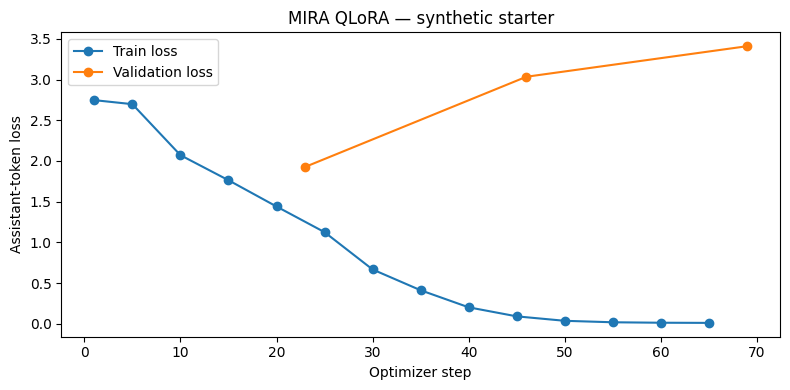

{
  "dataset": "SYNTHETIC STARTER / NOT EXPERT REVIEWED",
  "counts": {
    "train": 360,
    "validation": 45,
    "test": 45
  },
  "baseline": {
    "base_test_loss": 2.7213339805603027,
    "base_test_model_preparation_time": 0.0116,
    "base_test_runtime": 17.0242,
    "base_test_samples_per_second": 2.643,
    "base_test_steps_per_second": 2.643
  },
  "finetuned": {
    "finetuned_test_loss": 1.56097412109375,
    "finetuned_test_model_preparation_time": 0.0116,
    "finetuned_test_runtime": 12.076,
    "finetuned_test_samples_per_second": 3.726,
    "finetuned_test_steps_per_second": 3.726,
    "epoch": 3.0
  },
  "test_perplexity": 4.763459171878514,
  "train": {
    "train_runtime": 1017.1849,
    "train_samples_per_second": 1.062,
    "train_steps_per_second": 0.068,
    "total_flos": 6348422853623808.0,
    "train_loss": 0.765372738296139,
    "epoch": 3.0
  },
  "smoke_test_only": false,
  "note": "Loss/perplexity is not answer accuracy. Review factuality and unsupported 

In [12]:
import matplotlib.pyplot as plt

test_metrics = trainer.evaluate(encoded["test"], metric_key_prefix="finetuned_test")
loss = float(test_metrics["finetuned_test_loss"])
results = {
    "dataset": "SYNTHETIC STARTER / NOT EXPERT REVIEWED", "counts": manifest["counts"],
    "baseline": baseline_metrics, "finetuned": test_metrics,
    "test_perplexity": math.exp(loss) if loss < 50 else None,
    "train": train_result.metrics, "smoke_test_only": SMOKE_TEST_ONLY,
    "note": "Loss/perplexity is not answer accuracy. Review factuality and unsupported product claims manually. Do not tune on test.",
}
ADAPTER_DIR.mkdir(exist_ok=True)
model.save_pretrained(str(ADAPTER_DIR), safe_serialization=True)
tokenizer.save_pretrained(str(ADAPTER_DIR))
assert (ADAPTER_DIR / "adapter_config.json").exists()
assert (ADAPTER_DIR / "adapter_model.safetensors").exists()
(ADAPTER_DIR / "system_prompt.txt").write_text(SYSTEM_PROMPT + "\n", encoding="utf-8")
(ADAPTER_DIR / "run_config.json").write_text(json.dumps(run_config, indent=2), encoding="utf-8")
(ADAPTER_DIR / "metrics.json").write_text(json.dumps(results, ensure_ascii=False, indent=2), encoding="utf-8")
(ADAPTER_DIR / "trainer_history.json").write_text(json.dumps(trainer.state.log_history, indent=2), encoding="utf-8")
(ADAPTER_DIR / "dataset_manifest.json").write_text(json.dumps(manifest, ensure_ascii=False, indent=2), encoding="utf-8")
history = trainer.state.log_history
fig, ax = plt.subplots(figsize=(8, 4))
for key, name in (("loss", "Train loss"), ("eval_loss", "Validation loss")):
    points = [row for row in history if key in row]
    ax.plot([row["step"] for row in points], [row[key] for row in points], marker="o", label=name)
ax.set(xlabel="Optimizer step", ylabel="Assistant-token loss", title="MIRA QLoRA — synthetic starter")
ax.legend()
fig.tight_layout()
fig.savefig(ADAPTER_DIR / "loss.png", dpi=160)
plt.show()
print(json.dumps(results, ensure_ascii=False, indent=2))


## 10. So sánh câu trả lời trước/sau — đánh giá thủ công, không tự gọi đây là accuracy


In [13]:
comparison = []
for row in review_cases:
    after = generate_reply(row["messages"][:-1])
    item = {"id": row["id"], "topic": row["topic"], "messages": row["messages"][:-1],
        "reference": row["messages"][-1]["content"], "base": before_answers[row["id"]], "finetuned": after,
        "manual_review": {"factuality_0_to_2": None, "context_0_to_2": None, "no_invented_catalog_0_to_2": None, "vietnamese_clarity_0_to_2": None}}
    comparison.append(item)
    print("\nUSER:", row["messages"][-2]["content"], "\nBASE:", item["base"], "\nFINETUNED:", after)
(ADAPTER_DIR / "before_after.jsonl").write_text("".join(json.dumps(item, ensure_ascii=False) + "\n" for item in comparison), encoding="utf-8")
print("Chấm từng tiêu chí: 0 sai / 1 một phần / 2 đạt. Kiểm tra cả giá, tồn kho, chính sách và lịch sử. Không dùng cùng test này để chọn hyperparameters.")


/usr/local/lib/python3.13/dist-packages/bitsandbytes/backends/cuda/ops.py:464: FutureWarning: _check_is_size will be removed in a future PyTorch release along with guard_size_oblivious.     Use _check(i >= 0) instead.
  torch._check_is_size(blocksize)



USER: Nhẫn Flora hôm nay bao nhiêu tiền, còn size 14 không? 
BASE: Nhẫn Flora hôm nay giá khoảng 2,500,000 đồng. Về kích cỡ size 14, tôi chưa tìm thấy thông tin về tồn kho. Bạn có thể liên hệ trực tiếp với cửa hàng để kiểm tra nhé. 
FINETUNED: Mình chưa có giá và size 14 hiện tại. Bạn hãy kiểm tra bảng size và giá của mẫu này trên trang sản phẩm; nếu muốn mua, hãy chọn size phù hợp rồi gửi mã cho nhân viên hỗ trợ.

USER: Đổi sang vàng 14K, giữ nguyên ngân sách. 
BASE: Tất nhiên, bạn muốn tìm dây chuyền vàng 14K với ngân sách là 5 triệu đồng. Bạn có thể thêm bất kỳ yêu cầu nào khác không? 
FINETUNED: Mình thay dây chuyền sang vàng 14K, vẫn giữ ngân sách tối đa 5 triệu.

USER: MIRA ơi, Vàng trắng có phải bạch kim không? 
BASE: Vàng trắng thường được làm từ hợp kim vàng và bạc, chứ không phải bạch kim. Bạn có muốn tìm hiểu về các loại trang sức khác không? 
FINETUNED: Mình chưa thể xác nhận loại kim loại này. Bạn hãy kiểm tra bảng thành phần của sản phẩm cụ thể; nếu có thể, hãy gửi mã sả

## 11. Kiểm tra nạp lại adapter — giải phóng model cũ trước để tránh gấp đôi VRAM


In [14]:
from peft import PeftModel

del trainer, model
gc.collect()
torch.cuda.empty_cache()
model = PeftModel.from_pretrained(load_base(), str(ADAPTER_DIR), is_trainable=False)
model.eval()
print("Adapter đã nạp lại:", generate_reply([
    {"role": "system", "content": SYSTEM_PROMPT},
    {"role": "user", "content": "Tôi muốn mua nhẫn bạc nhưng chưa biết size."},
]))


Loading checkpoint shards:   0%|          | 0/2 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/bitsandbytes/backends/cuda/ops.py:212: FutureWarning: _check_is_size will be removed in a future PyTorch release along with guard_size_oblivious.     Use _check(i >= 0) instead.
  torch._check_is_size(blocksize)


Adapter đã nạp lại: Mình ghi nhận bạn muốn mua nhẫn bạc và chưa có size. Bạn hãy chọn một size tiêu chuẩn hoặc nhắn mình size đang đeo để mình kiểm tra.


## 12. Tải kết quả — chỉ adapter và báo cáo, không chứa base model


In [15]:
import shutil

(ADAPTER_DIR / "README.md").write_text(
    "# MIRA QLoRA adapter\n\nBase: " + MODEL_ID + "\n\n"
    "This ZIP contains LoRA adapter weights, not a standalone model. Load with the same base model and compatible tokenizer. "
    "Model license: https://huggingface.co/Qwen/Qwen2.5-3B-Instruct/blob/main/LICENSE\n\n"
    "Dataset is synthetic and has not received expert review. See metrics.json and before_after.jsonl; no production-accuracy claim. "
    "Live catalog, order/payment status and store policies must come from application APIs. This adapter does not modify the MIRA web server or replace Gemini automatically.\n",
    encoding="utf-8",
)
archive = shutil.make_archive("/content/mira_qlora_adapter", "zip", root_dir=str(ADAPTER_DIR))
print("Đã xuất:", archive)
files.download(archive)


Đã xuất: /content/mira_qlora_adapter.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>